<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_Part_2_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  data_path = '/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt'
except ImportError:  # running locally
  data_path = 'Data/names.txt'
with open(data_path,'r') as f:
  text = f.read().splitlines()

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
words = text
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
# build the volcabulary of charaters and mappings to/from integers
chars = sorted(list(set(''.join(words))))

stoi = {s:i+1 for i , s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
# print(itos)

In [6]:
block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  # print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    # print(''.join(itos[i] for i in context), '------------>', itos[ix])
    context = context[1:] + [ix]
X = torch.tensor(X)
Y = torch.tensor(Y)


In [7]:
X.shape, X.dtype, Y.shape, Y.dtype,

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [8]:
X[1]

tensor([0, 0, 5])

In [81]:
# build datasets

def build_dateset(words):
    block_size = 3
    X, Y = [] , []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))


Xtr, Ytr = build_dateset(words[:n1])
Xval, Yval = build_dateset(words[n1:n2])
Xte, Yte = build_dateset(words[n2:])

torch.Size([182441, 3]) torch.Size([182441])
torch.Size([22902, 3]) torch.Size([22902])
torch.Size([22803, 3]) torch.Size([22803])


In [103]:
C = torch.randn((27,2))

In [10]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [11]:
F.one_hot(torch.tensor(5), num_classes=27).float()

tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [12]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [13]:
torch.cat([emb[:,0,:], emb[:,1,:], emb[:,2,:]], 1).shape

torch.Size([228146, 6])

In [14]:
len(torch.unbind(emb,1))

3

In [15]:
torch.cat(torch.unbind(emb,1),1).shape

torch.Size([228146, 6])

In [16]:
a = torch.arange(18)
a.shape

torch.Size([18])

In [17]:
a.view(3,3, 2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [18]:
# a.untyped_storage()

In [19]:
emb.shape

torch.Size([228146, 3, 2])

In [21]:
emb.view(228146,6) == torch.cat(torch.unbind(emb,1),1)

tensor([[True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        ...,
        [True, True, True, True, True, True],
        [True, True, True, True, True, True],
        [True, True, True, True, True, True]])

In [22]:
h = torch.tanh(emb.view(-1,emb.shape[1]*emb.shape[2]) @ W1 + b1)
h.shape

torch.Size([228146, 100])

In [23]:
h.shape

torch.Size([228146, 100])

In [24]:
W2= torch.randn((100,27))
b2 = torch.rand(27)

In [25]:
logits = h @ W2 +b2

In [26]:
logits.shape

torch.Size([228146, 27])

In [27]:
logits.shape

torch.Size([228146, 27])

In [28]:
counts = logits.exp()
probs = counts / counts.sum(1,keepdim=True)
probs[0]

tensor([5.1487e-11, 9.8997e-01, 2.1473e-06, 1.4142e-04, 7.1797e-03, 2.9354e-12,
        1.5882e-06, 3.4822e-06, 3.1179e-06, 1.7469e-07, 4.8107e-07, 1.2775e-08,
        2.1621e-03, 1.3021e-05, 3.1700e-07, 3.8083e-10, 6.0683e-05, 7.5398e-13,
        3.1163e-13, 1.0518e-09, 1.9646e-08, 7.4910e-07, 2.5528e-08, 3.3480e-06,
        4.5547e-04, 1.1525e-08, 2.2308e-10])

In [29]:
Y

tensor([ 5, 13, 13,  ..., 26, 24,  0])

In [30]:
torch.arange(32)

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

In [31]:
loss = -probs[torch.arange(32), Y].log().mean()
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [36]:
emb = C[X]
h = torch.tanh(emb.view(-1,emb.shape[1]*emb.shape[2]) @ W1 +b1)
logits = h @ W2 +b2
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)
loss = - probs[torch.arange(32), Y].log().mean()
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [72]:
F.cross_entropy(logits, Y)

ValueError: Expected input batch_size (32) to match target batch_size (228146).

In [119]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,10),generator=g)
W1 = torch.randn((30,200), generator=g)
b1 = torch.randn(200,generator=g)
W2 = torch.randn((200,27),generator=g)
b2 = torch.rand(27,generator=g)
parameters = [C, W1, b1, W2, b2]

In [120]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [84]:
lre = torch.linspace(-3,0,1000)
lrs = 10**lre


In [122]:
for p in parameters:
  p.requires_grad=True

In [121]:
lri = []
lossi = []
stepi = []

In [139]:


for i in range(200000):
    # mini batch construct
  ix = torch.randint(0,Xtr.shape[0], (32,))
  # forward pass
  emb = C[Xtr[ix]] # (32,3,2)
  h = torch.tanh(emb.view(-1,30) @ W1 +b1) # 32* 100
  logits = h @ W2 + b2 # 32*27
  loss= F.cross_entropy(logits, Ytr[ix])
  # print(loss.item())

  # backward pass
  for p in parameters:
    p.grad=None
  loss.backward()
  # udpate
  # lr = lrs[i]
  lr = 10**(-1) if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr*p.grad
      
  #track stats
  # lri.append(lre[i])
  lossi.append(loss.log10().item())
  stepi.append(i)
# print(loss.item())


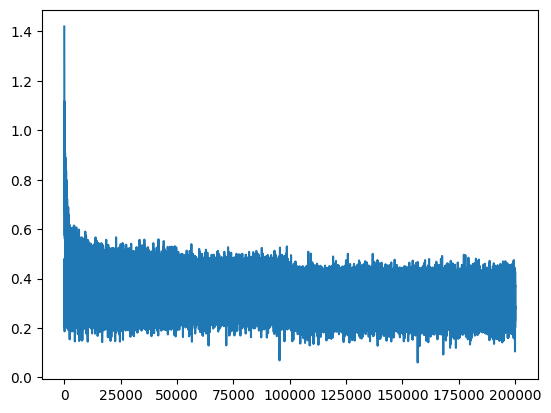

In [140]:
plt.plot(stepi,lossi)

In [32]:
torch.randint(0,X.shape[0],(32,))

tensor([ 18983,  39491,  95738,  36566, 164808,  59948,  21223,  87931,  48475,
        118227, 181767,  59285,   6537, 210660, 184011,  67793, 156685,  78062,
         48214, 165393, 212572, 110793, 139174, 208823,  78360,  57353,   9669,
        100421, 217719, 155866, 139064, 169479])

In [141]:
  emb = C[Xtr] # (32,3,2)
  h = torch.tanh(emb.view(-1,30) @ W1 +b1) # 32* 100
  logits = h @ W2 + b2 # 32*27
  loss= F.cross_entropy(logits, Ytr)
  loss

tensor(2.1021, grad_fn=<NllLossBackward0>)

In [142]:
  emb = C[Xval] # (32,3,2)
  h = torch.tanh(emb.view(-1,30) @ W1 +b1) # 32* 100
  logits = h @ W2 + b2 # 32*27
  loss= F.cross_entropy(logits, Yval)
  loss

tensor(2.1629, grad_fn=<NllLossBackward0>)

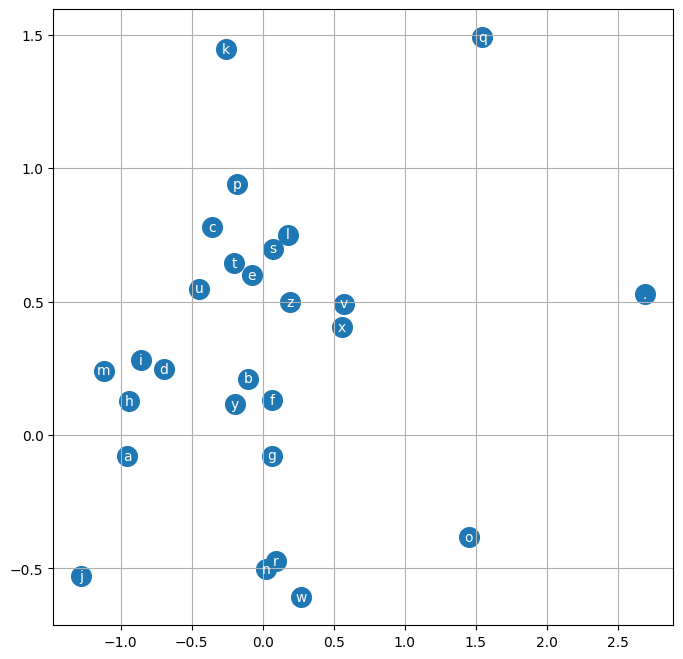

In [143]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")
plt.grid('minor')

In [146]:
# training, validation, tests splits
# 70% 20% 10%
g= torch.Generator().manual_seed(123123123)

for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1,-1) @ W1 +b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix==0:
            break
    print(''.join(itos[i] for i in out))


andhi.
zele.
nymone.
chiza.
ril.
sanyor.
tena.
niko.
aza.
kislaelan.
palie.
adtuclen.
sochuul.
ahdimamery.
eihan.
aido.
ari.
loyalma.
suria.
aluusemruan.
